# 07 Sentence vectors on titles
In notebook 04 I compared titles with TF-IDF, which only matches words. Here I turned every title into a vector with a ready-made sentence model, so titles with a similar meaning end up close together. I scored it with my ratings next to the other methods. The model was used as it is, with no training. Nothing here uses the 20 locked final products.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.rcParams.update(
    {"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREEN, ORANGE = "#4c78a8", "#54a24b", "#f58518"
pd.set_option("display.width", 170)

results = root / "results"
speed = json.loads((results / "text_embedding_speed.json").read_text(encoding="utf-8"))
coverage = json.loads(
    (results / "dev_text_vector_search_coverage.json").read_text(encoding="utf-8")
)
board = pd.read_csv(results / "dev_text_vector_scoreboard.csv").set_index("method")
pairs = pd.read_csv(results / "dev_text_vector_pairwise.csv")
print("loaded the saved results")

loaded the saved results


## 1. The model
I used `all-MiniLM-L6-v2` from Hugging Face. It is small (about 90 MB), it is free to use (Apache-2.0 licence), and it maps a sentence to 384 numbers.

Its authors trained it on over a billion pairs of sentences, such as questions with answers and titles with descriptions, so that pairs which belong together get close vectors. It is meant for search and finding similar sentences, and it cuts text longer than 256 word pieces. My titles are much shorter than that. It was not trained on shopping titles, so it may be weaker on brand names and size words.

## 2. Turning titles into vectors

In [2]:
display(
    pd.DataFrame(
        {
            "titles": [f"{speed['titles']:,}"],
            "numbers per title": [speed["dimensions"]],
            "empty titles": [speed["empty_titles"]],
            "longest title (words)": [speed["longest_title_words"]],
            "seconds": [speed["seconds"]],
        },
        index=["all-MiniLM-L6-v2"],
    )
)

,titles,numbers per title,empty titles,longest title (words),seconds
all-MiniLM-L6-v2,"29,529",384,0,93,31.5


### What this shows
Every title became a vector, with no failures. It took about half a minute on my laptop, which is much faster than the pictures.

## 3. Searching
For each of my 30 development products, the model found the 10 closest titles. The 20 locked products can never be returned. Results that I had already rated kept their rating. I rated the new ones myself, without seeing which method found them, so every method is scored with the same ratings.

In [3]:
print(f"results: {coverage['results_total']} (10 for each of {coverage['dev_products']} products)")
print(f"already rated before: {coverage['already_rated']}")
print(f"rated now: {coverage['new_results_to_rate']}")
print(
    f"copies left out: {coverage['dropped_copy_of_query']} of the searched product, "
    f"{coverage['dropped_copy_of_result']} of another result"
)

results: 300 (10 for each of 30 products)
already rated before: 153
rated now: 147
copies left out: 2 of the searched product, 3 of another result


## 4. Scoreboard
Each method returns its 10 most similar products for the 30 development products. **nDCG@10** gives more credit to good results near the top. **Precision@10** is the share of the top 10 that I rated 1 or 2.

In [4]:
labels = {
    "image_clip_all": "CLIP, whole catalogue (pictures)",
    "text_vectors": "Sentence vectors (titles)",
    "baseline": "Title (TF-IDF) and attributes (my baseline)",
    "title_only": "TF-IDF, title only",
    "attributes_only": "Attributes only",
}
table = pd.DataFrame(
    {
        "Method": list(labels.values()),
        "nDCG@10": [round(board.loc[m, "ndcg_at_10"], 3) for m in labels],
        "Precision@10": [round(board.loc[m, "precision_at_10"], 2) for m in labels],
    }
).set_index("Method")
display(table)

,nDCG@10,Precision@10
Method,,
"CLIP, whole catalogue (pictures)",0.751,0.85
Sentence vectors (titles),0.662,0.76
Title (TF-IDF) and attributes (my baseline),0.637,0.74
"TF-IDF, title only",0.500,0.55
Attributes only,0.422,0.62


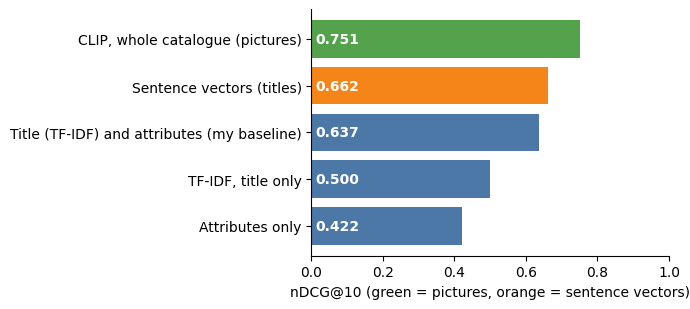

In [5]:
fig, ax = plt.subplots()
names = list(labels)[::-1]
values = [board.loc[m, "ndcg_at_10"] for m in names]
colours = [
    GREEN if m == "image_clip_all" else ORANGE if m == "text_vectors" else BLUE for m in names
]
ax.barh([labels[m] for m in names], values, color=colours)
for i, v in enumerate(values):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 (green = pictures, orange = sentence vectors)")
plt.tight_layout()
plt.show()

### What this shows
CLIP on pictures has the highest score. Sentence vectors come second, a little above my baseline. TF-IDF on titles alone and attributes alone are lower.

## 5. Are the differences real or luck?
For each pair of methods, I compared the nDCG@10 on the same products. If the difference could come from the choice of products, I call it luck.

In [6]:
wanted = [
    ("text_vectors", "title_only"),
    ("text_vectors", "attributes_only"),
    ("text_vectors", "baseline"),
    ("image_clip_all", "text_vectors"),
]
rows = []
for a, b in wanted:
    hit = pairs[
        ((pairs["first"] == a) & (pairs["second"] == b))
        | ((pairs["first"] == b) & (pairs["second"] == a))
    ].iloc[0]
    sign = 1 if hit["first"] == a else -1
    rows.append(
        {
            "comparison": f"{labels[a]} minus {labels[b]}",
            "difference": f"{sign * hit['ndcg_difference']:+.3f}",
            "verdict": "real" if hit["difference_is_real"] else "could be luck",
        }
    )
display(pd.DataFrame(rows).set_index("comparison"))

,difference,verdict
comparison,,
"Sentence vectors (titles) minus TF-IDF, title only",+0.163,real
Sentence vectors (titles) minus Attributes only,+0.241,real
Sentence vectors (titles) minus Title (TF-IDF) and attributes (my baseline),+0.026,could be luck
"CLIP, whole catalogue (pictures) minus Sentence vectors (titles)",+0.088,could be luck


### What this shows
Sentence vectors are clearly better than TF-IDF on titles and clearly better than attributes alone. Against my baseline, and CLIP against sentence vectors, the gaps could be luck with 30 products, so I do not call a winner there.

## 6. Recorded in MLflow
All five runs are saved in MLflow with their settings and scores. This is MLflow's comparison page:

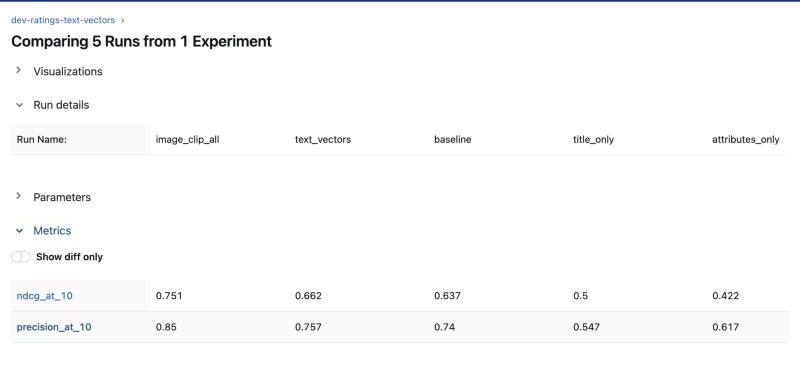

In [7]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_text_vector_runs.png", width=900)

## 7. Conclusion


**What I wanted to know:** does a model that understands the meaning of titles find better matches than TF-IDF, which only matches words?

**What I did.** I took a ready-made sentence model, `all-MiniLM-L6-v2`, and turned all 29,529 product titles into lists of numbers. Titles with similar meaning get numbers that are close together. I used the model as it is, with no training. For my 30 test products I found the 10 closest titles. I rated the new results myself, without knowing which method found them. I used one set of my ratings to check every method, so the comparison is fair, and I show only one copy of each item.

| Method | nDCG@10 | Precision@10 |
|---|---|---|
| CLIP, whole catalogue (pictures) | 0.751 | 0.85 |
| Sentence vectors (titles) | 0.662 | 0.76 |
| Title (TF-IDF) and attributes (my baseline) | 0.637 | 0.74 |
| TF-IDF, title only | 0.500 | 0.55 |
| Attributes only | 0.422 | 0.62 |

Precision@10 is how many of the top 10 I rated 1 or 2.

**What I found**

- Sentence vectors are clearly better than TF-IDF on titles. Understanding meaning helps more than matching words.
- Sentence vectors and my baseline score about the same. With only 30 products I can't say which is better.
- CLIP is still the highest, but its gap over sentence vectors is small enough to be luck.
- Pictures and titles each find good matches on their own, so I want to try using them together.

**What I can't say yet**

- I tested only 30 products, and I was the only person rating.
- The model was trained on questions, answers and captions, not on shopping titles, so it may miss brand names and size words.
- I haven't touched my 20 final test products.

**What I do next.** I will mix text, CLIP and attributes into one hybrid search, and tune the weights using my ratings.